# Leakage-controlled High-vs-Low expression pipeline (revised)

**One run = one target gene** (`CONFIG["TARGET_GENE"]`). Run the notebook once for DHODH and once for SHMT2.

What this version fixes relative to the original notebook (details in the response document):

| # | Problem in the original | Fix here |
|---|---|---|
| 1.1 | Arms defined by the target gene, then the target (and its co-expressed genes) were allowed into the classifier | Target gene **and every gene with &#124;Spearman rho&#124; >= `RHO_EXCLUDE`** removed from *every* analysis; feature selection moved **inside** the cross-validation folds; permutation test repeats the **whole** pipeline; leakage-sensitivity analysis added |
| 1.2 | "Pseudotime" read as time; K and n not scale-invariant; no fit statistics; no error bars | Pseudotime built from leakage-free genes only, on one pooled axis; ratio-scaled expression; fits compared with constant/linear models (R², AICc); bootstrap CIs; identifiability flags; PINN bootstrap CIs and ground-truth validation |
| 1.3 | Tally of nominal p < 0.05 over undefined modules | Pre-specified contrasts only, Benjamini-Hochberg across the family, modules reduced to those that are described and reported |

Removed as unnecessary for the reported analysis: prevalence estimation, PC-algorithm causal discovery, VAE/GCN deep learning, Gompertz growth model, graphical lasso, SHAP, synthetic-data generator, URL downloader, interim figures.

## 1. Setup and configuration

In [1]:
from __future__ import annotations
import json, os, sys, time, warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import odeint
from scipy.optimize import least_squares
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"      # also silences the joblib worker processes (they ignore the line above)

try:
    import torch, torch.nn as nn
    HAS_TORCH = True
except Exception:
    HAS_TORCH = False

# ============================ EDIT HERE ====================================
CONFIG: Dict = dict(
    TARGET_GENE="DHODH",                      # "DHODH" or "SHMT2": run the notebook once per target
    EXPRESSION_SOURCE="gene_expression_genemajor.xlsx",   # genes = rows, patients = columns
    EXPRESSION_SHEET="expression",
    GENE_ID_COL="gene_id",
    # Arms. "median_split" = High/Low split of the target gene (n/2 each).
    # If CLINICAL_SOURCE is given its GROUP_COL is only used to check agreement.
    CLINICAL_SOURCE="clinical.xlsx", CLINICAL_SHEET="clinical",
    PATIENT_ID_COL="patient_id", GROUP_COL="group",

    # ---- leakage control ----
    RHO_EXCLUDE=0.5,          # remove genes with |Spearman rho| with the target >= this value
    N_TOP_GENES=2000,         # most-variable retained genes entering the analyses
    N_FILTER=200,             # genes kept by the in-fold univariate filter
    # ---- classification ----
    CV_FOLDS=5, CV_REPEATS=5, N_PERM=200, N_BOOT_AUC=2000, RUN_GBM=True,
    # ---- co-expression modules ----
    N_MODULE_GENES=300, MODULE_MIN_CORR=0.4, MODULE_MIN_SIZE=10,
    # ---- dynamics / PINN ----
    N_BINS=20, N_BOOT_HILL=100, N_STARTS=8,
    N_PINN_RESTARTS=6, N_PINN_BOOT=30, PINN_EPOCHS=2500, PINN_EPOCHS_BOOT=1500, N_VALID_REPS=5,
    PINN_LBFGS=100,           # L-BFGS polish iterations (the slowest step; 0 = skip)
    PINN_HIDDEN=64, PINN_NCOL=256, PINN_THREADS=8,   # network width, collocation points, CPU threads
    PINN_DEVICE="cpu",        # "cpu" (recommended for this tiny network), "cuda", "mps" or "auto"
    PINN_PARALLEL=False,      # True = run PINN bootstraps in parallel CPU processes (1 thread each)
    RUN_PINN=True, RUN_PINN_VALIDATION=True,         # set False to skip section 6 / its validation

    # ---- runtime / output ----
    SEED=42, N_JOBS=-1, FAST_MODE=False,
    OUTPUT_DIR="Results", DPI=1200,
)
# ===========================================================================

if CONFIG["FAST_MODE"]:      # smoke test only: do NOT report these numbers
    CONFIG.update(CV_REPEATS=1, N_PERM=20, N_BOOT_AUC=200, N_BOOT_HILL=15, N_STARTS=3,
                  N_PINN_RESTARTS=1, N_PINN_BOOT=2, PINN_EPOCHS=150, PINN_EPOCHS_BOOT=100, N_VALID_REPS=1,
                  PINN_LBFGS=0, PINN_HIDDEN=32, PINN_NCOL=64)

TARGET = CONFIG["TARGET_GENE"]
SEED = CONFIG["SEED"]
RNG = np.random.default_rng(SEED)
np.random.seed(SEED)
OUT = Path(CONFIG["OUTPUT_DIR"]) / TARGET
OUT.mkdir(parents=True, exist_ok=True)
TABLES: Dict[str, pd.DataFrame] = {}          # every table goes to one Excel workbook

C_HIGH, C_LOW, C_ACC, C_NEU, C_DARK = "#C2185B", "#00838F", "#F9A825", "#90A4AE", "#37474F"
COL = {"High": C_HIGH, "Low": C_LOW}
mpl.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": C_DARK, "axes.grid": True, "grid.color": "#ECEFF1",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "font.family": "DejaVu Sans"})


def hardware_report():
    import joblib, sklearn
    cores = joblib.cpu_count()
    nj = CONFIG["N_JOBS"]; used = cores if nj in (-1, None) else (max(1, cores + 1 + nj) if nj < 0 else nj)
    print("=== hardware / runtime ===")
    print(f"CPU cores visible: {os.cpu_count()} (joblib: {cores}); worker processes used for CV permutations, "
          f"leakage scenarios and Hill bootstraps: {used}")
    print(f"scikit-learn {sklearn.__version__}: classifiers are CPU-only (no GPU path)")
    if HAS_TORCH:
        mps = bool(getattr(torch.backends, "mps", None) and torch.backends.mps.is_available())
        print(f"PyTorch {torch.__version__}: CUDA GPU available = {torch.cuda.is_available()}"
              + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else "")
              + f"; Apple MPS available = {mps}; PINN device requested = {CONFIG['PINN_DEVICE']!r}")
    else:
        print("PyTorch: not installed -> PINN section will be skipped")


hardware_report()


def save_fig(fig, name):
    for ext in ("png",):
        fig.savefig(OUT / f"{name}.{ext}", dpi=CONFIG["DPI"], bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig)


def bh(p):
    """Benjamini-Hochberg q-values (NaN-safe)."""
    p = np.asarray(p, float); q = np.full(p.shape, np.nan); ok = np.isfinite(p)
    pv = p[ok]; n = len(pv)
    if n == 0:
        return q
    o = np.argsort(pv); r = pv[o] * n / np.arange(1, n + 1)
    r = np.minimum.accumulate(r[::-1])[::-1]; out = np.empty(n); out[o] = np.clip(r, 0, 1)
    q[ok] = out
    return q


def rank_biserial(a, b):
    U = stats.mannwhitneyu(a, b, alternative="two-sided")
    return 2 * U.statistic / (len(a) * len(b)) - 1, U.pvalue


def spearman_vs(vec, M):
    """Spearman correlation of vec with every column of M (vectorised)."""
    rv = stats.rankdata(vec); rM = stats.rankdata(M, axis=0)
    rv = (rv - rv.mean()) / (rv.std() + 1e-12)
    rM = (rM - rM.mean(0)) / (rM.std(0) + 1e-12)
    return (rM * rv[:, None]).mean(0)

=== hardware / runtime ===
CPU cores visible: 8 (joblib: 8); worker processes used for CV permutations, leakage scenarios and Hill bootstraps: 8
scikit-learn 1.9.1: classifiers are CPU-only (no GPU path)
PyTorch 2.11.0: CUDA GPU available = False; Apple MPS available = False; PINN device requested = 'cpu'


## 2. Data, arm definition and leakage-control gene set

In [2]:
def read_table(path, sheet=None):
    p = Path(path).expanduser()
    if not p.exists():
        raise FileNotFoundError(f"{p} not found - fix CONFIG['EXPRESSION_SOURCE']")
    if p.suffix.lower() in (".xlsx", ".xls", ".xlsm"):
        names = pd.ExcelFile(p).sheet_names
        return pd.read_excel(p, sheet_name=sheet if sheet in names else 0)
    return pd.read_csv(p, sep="\t" if p.suffix.lower() in (".tsv", ".txt") else ",")


raw = read_table(CONFIG["EXPRESSION_SOURCE"], CONFIG["EXPRESSION_SHEET"])
gcol = CONFIG["GENE_ID_COL"]
if gcol not in raw.columns:
    raw = raw.rename(columns={raw.columns[0]: gcol})
raw[gcol] = raw[gcol].astype(str).str.strip()
expr = raw.set_index(gcol).apply(pd.to_numeric, errors="coerce")
if expr.index.duplicated().any():
    expr = expr.groupby(level=0).mean()
if expr.isna().to_numpy().any():
    expr = expr.T.fillna(expr.median(axis=1)).T.fillna(0.0)
expr = expr.loc[expr.std(axis=1) > 0]

PATIENTS = np.array([str(c) for c in expr.columns])
GENES = np.array([str(g) for g in expr.index])
X = np.ascontiguousarray(expr.to_numpy(float).T)               # patients x genes
n_pat, n_gen = X.shape

hit = np.where(np.char.upper(GENES) == TARGET.upper())[0]
if len(hit) != 1:
    raise KeyError(f"target gene {TARGET} found {len(hit)} times in the matrix")
T_IDX = int(hit[0])
t_expr = X[:, T_IDX]

# Arms: exact median split of the target gene (ordinal ranks break ties)
rk = stats.rankdata(t_expr, method="ordinal")
is_high = rk > n_pat / 2
hi, lo = is_high, ~is_high
y = is_high.astype(int)
print(f"{n_pat} patients x {n_gen:,} genes | target {TARGET} | High n={hi.sum()}, Low n={lo.sum()}")

if CONFIG["CLINICAL_SOURCE"]:                                  # optional consistency check
    clin = read_table(CONFIG["CLINICAL_SOURCE"], CONFIG["CLINICAL_SHEET"])
    g = clin.set_index(clin[CONFIG["PATIENT_ID_COL"]].astype(str))[CONFIG["GROUP_COL"]].astype(str).str.lower()
    g = g.reindex(PATIENTS)
    agree = (g.map({"high": 1, "low": 0}).to_numpy() == y).mean()
    print(f"agreement of median split with clinical group labels: {agree:.1%}")

# Genes that cannot be used as features: the target and everything co-expressed with it
RHO = spearman_vs(t_expr, X)
RHO[T_IDX] = 1.0


def excluded_mask(thr, drop_target=True):
    m = np.zeros(n_gen, bool)
    if thr is not None:
        m |= np.abs(RHO) >= thr
    if drop_target:
        m[T_IDX] = True
    return m


EXCL = excluded_mask(CONFIG["RHO_EXCLUDE"])
KEEP = np.where(~EXCL)[0]
print(f"excluded from every analysis: {EXCL.sum():,} genes (target + |rho| >= {CONFIG['RHO_EXCLUDE']}); "
      f"retained {len(KEEP):,}")
TABLES["excluded_genes"] = (pd.DataFrame({"gene": GENES[EXCL], "spearman_rho_with_target": RHO[EXCL]})
                            .sort_values("spearman_rho_with_target", key=np.abs, ascending=False))


def top_variable(keep_idx, n):
    v = X[:, keep_idx].var(0)
    return keep_idx[np.argsort(v)[::-1][:min(n, len(keep_idx))]]


TOP = top_variable(KEEP, CONFIG["N_TOP_GENES"])               # candidate feature set (leak-free)
Xc = X[:, TOP]

160 patients x 19,978 genes | target DHODH | High n=80, Low n=80
agreement of median split with clinical group labels: 56.2%
excluded from every analysis: 13 genes (target + |rho| >= 0.5); retained 19,965


## 3. Descriptive contrasts (QC, co-expression modules, differential expression)

In [3]:
CONTRASTS: List[dict] = []


def add_contrast(module, quantity, high, low, effect=None, p=None, note=""):
    CONTRASTS.append(dict(module=module, quantity=quantity, High=high, Low=low,
                          effect_size=effect, p_value=p, note=note))


# --- 1. QC (two pre-specified contrasts, computed on retained genes only)
samp_mean = X[:, KEEP].mean(1)
Pc = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(Xc))
for q, v in [("mean expression per patient", samp_mean), ("PC1 of retained genes", Pc[:, 0])]:
    r, p = rank_biserial(v[hi], v[lo])
    add_contrast("1. QC", q, float(v[hi].mean()), float(v[lo].mean()), r, p)


# --- 2. Co-expression modules built WITHOUT the target set
def build_modules(Xm, gene_ids, n_top, min_corr, min_size):
    top = np.argsort(Xm.var(0))[::-1][:n_top]
    R = np.corrcoef(stats.rankdata(Xm[:, top], axis=0).T)
    D = 1 - np.abs(R); np.fill_diagonal(D, 0)
    lab = fcluster(linkage(squareform(D, checks=False), "average"), t=1 - min_corr, criterion="distance")
    mods = [top[lab == l] for l in np.unique(lab) if (lab == l).sum() >= min_size]
    mods.sort(key=len, reverse=True)
    eig = {}
    for i, ix in enumerate(mods, 1):
        Z = StandardScaler().fit_transform(Xm[:, ix])
        pc = PCA(n_components=1, random_state=0).fit_transform(Z).ravel()
        if np.corrcoef(pc, Z.mean(1))[0, 1] < 0:
            pc = -pc
        eig[f"M{i}"] = pc
    return mods, pd.DataFrame(eig, index=PATIENTS)


MODS, EIG = build_modules(X[:, KEEP], KEEP, CONFIG["N_MODULE_GENES"],
                          CONFIG["MODULE_MIN_CORR"], CONFIG["MODULE_MIN_SIZE"])
rows = []
for i, c in enumerate(EIG.columns):
    r, p = rank_biserial(EIG[c].to_numpy()[hi], EIG[c].to_numpy()[lo])
    rows.append(dict(module=c, n_genes=len(MODS[i]), mean_High=EIG[c][hi].mean(),
                     mean_Low=EIG[c][lo].mean(), rank_biserial=r, p_value=p))
    add_contrast("2. Networks", f"eigengene {c} ({len(MODS[i])} genes)", float(EIG[c][hi].mean()),
                 float(EIG[c][lo].mean()), r, p)
EIG_CMP = pd.DataFrame(rows)
TABLES["module_eigengene_contrasts"] = EIG_CMP
print(f"{len(MODS)} co-expression modules (target set excluded)")

# --- differential expression (descriptive; not part of the contrast tally)
A, B = Xc[hi], Xc[lo]
U, p = stats.mannwhitneyu(A, B, axis=0)
DE = pd.DataFrame({"gene": GENES[TOP], "mean_High": A.mean(0), "mean_Low": B.mean(0),
                   "mean_diff": A.mean(0) - B.mean(0),
                   "rank_biserial": 2 * U / (hi.sum() * lo.sum()) - 1, "p_value": p})
DE["fdr_q"] = bh(DE["p_value"].to_numpy())
TABLES["DE_retained_genes"] = DE.sort_values("p_value").reset_index(drop=True)
print(f"DE: {(DE.fdr_q < 0.10).sum()} / {len(DE)} retained genes at FDR < 0.10 (descriptive)")

6 co-expression modules (target set excluded)
DE: 334 / 2000 retained genes at FDR < 0.10 (descriptive)


## 4. Leakage-controlled classification

In [4]:
# Every data-dependent step (univariate filter, scaling, L1 penalty) is re-fitted inside each
# training fold; the test fold is never seen. The permutation null repeats the WHOLE pipeline.
def l1_logit_cv(seed):
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    kw = dict(Cs=10, cv=cv, scoring="roc_auc", max_iter=2000, solver="liblinear", random_state=seed)
    for extra in (dict(l1_ratios=(1.0,), use_legacy_attributes=False),   # scikit-learn >= 1.8
                  dict(l1_ratios=(1.0,)),
                  dict(penalty="l1")):                                    # older versions
        try:
            return LogisticRegressionCV(**extra, **kw)
        except TypeError:
            continue
    raise RuntimeError("could not build L1 logistic regression")


def top_k_by_t(Xtr, ytr, k):
    a, b = Xtr[ytr == 1], Xtr[ytr == 0]
    t = (a.mean(0) - b.mean(0)) / np.sqrt(a.var(0, ddof=1) / len(a) + b.var(0, ddof=1) / len(b) + 1e-12)
    return np.argsort(-np.abs(t))[:k]


def fit_predict(Xtr, ytr, Xte, seed, k, model="logit"):
    idx = top_k_by_t(Xtr, ytr, k)
    if model == "gbm":
        m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                           random_state=seed).fit(Xtr[:, idx], ytr)
        return m.predict_proba(Xte[:, idx])[:, 1], idx[:0]
    sc = StandardScaler().fit(Xtr[:, idx])
    m = l1_logit_cv(seed).fit(sc.transform(Xtr[:, idx]), ytr)
    return m.predict_proba(sc.transform(Xte[:, idx]))[:, 1], idx[np.flatnonzero(m.coef_.ravel())]


def run_cv(Xm, yv, k, seed, repeats, model="logit"):
    oof = np.zeros((repeats, len(yv))); fold_auc, sel = [], []
    for r in range(repeats):
        for tr, te in StratifiedKFold(CONFIG["CV_FOLDS"], shuffle=True, random_state=seed + r).split(Xm, yv):
            p, nz = fit_predict(Xm[tr], yv[tr], Xm[te], seed + r, k, model)
            oof[r, te] = p; fold_auc.append(roc_auc_score(yv[te], p)); sel.append(nz)
    return dict(oof=oof, fold_auc=np.array(fold_auc), sel=sel,
                rep_auc=np.array([roc_auc_score(yv, o) for o in oof]))


def perm_auc(Xm, yv, k, seed):
    yp = np.random.default_rng(seed).permutation(yv)
    return run_cv(Xm, yp, k, seed, 1)["rep_auc"][0]


t0 = time.time()
CV = run_cv(Xc, y, CONFIG["N_FILTER"], SEED, CONFIG["CV_REPEATS"])
oof = CV["oof"].mean(0)                                        # repeat-averaged out-of-fold P(High)
auc_obs = float(CV["rep_auc"].mean())
bt = np.random.default_rng(SEED)
boots = []
for _ in range(CONFIG["N_BOOT_AUC"]):
    ix = bt.integers(0, n_pat, n_pat)
    if 0 < y[ix].sum() < n_pat:
        boots.append(roc_auc_score(y[ix], oof[ix]))
auc_ci = np.percentile(boots, [2.5, 97.5])
NULL = np.array(Parallel(n_jobs=CONFIG["N_JOBS"])(
    delayed(perm_auc)(Xc, y, CONFIG["N_FILTER"], 10_000 + i) for i in range(CONFIG["N_PERM"])))
p_perm = (np.sum(NULL >= auc_obs) + 1) / (len(NULL) + 1)
print(f"leak-free AUC = {auc_obs:.3f} (95% CI {auc_ci[0]:.3f}-{auc_ci[1]:.3f}); "
      f"null {NULL.mean():.3f} +/- {NULL.std():.3f}; permutation p = {p_perm:.4f} "
      f"(minimum attainable {1/(len(NULL)+1):.4f})  [{time.time()-t0:.0f}s]")

perf = dict(target=TARGET, n_features_candidate=len(TOP), n_excluded=int(EXCL.sum()),
            rho_exclude=CONFIG["RHO_EXCLUDE"], auc_mean_over_repeats=auc_obs,
            auc_ci_low=auc_ci[0], auc_ci_high=auc_ci[1],
            fold_auc_mean=float(CV["fold_auc"].mean()), fold_auc_sd=float(CV["fold_auc"].std()),
            null_mean=float(NULL.mean()), null_sd=float(NULL.std()), n_perm=len(NULL), p_perm=float(p_perm))
if CONFIG["RUN_GBM"]:
    G = run_cv(Xc, y, CONFIG["N_FILTER"], SEED, 1, model="gbm")
    perf["gbm_auc_sensitivity"] = float(G["rep_auc"][0])
    print(f"gradient-boosting sensitivity AUC = {perf['gbm_auc_sensitivity']:.3f} (no permutation test)")
TABLES["classifier_performance"] = pd.DataFrame([perf])
TABLES["classifier_oof"] = pd.DataFrame({"patient": PATIENTS, "arm": np.where(hi, "High", "Low"), "oof_P_high": oof})
freq = pd.Series(np.concatenate(CV["sel"])).value_counts() / len(CV["sel"])
TABLES["feature_selection_frequency"] = pd.DataFrame({"gene": GENES[TOP][freq.index.to_numpy()],
                                                      "fraction_of_folds_selected": freq.to_numpy()})
add_contrast("3. Classification", "leak-free nested-CV AUC vs permutation null", auc_obs,
             float(NULL.mean()), None, float(p_perm), f"{len(NULL)} full-pipeline permutations")

# --- leakage-sensitivity analysis: how much of the AUC is carried by the defining gene and its neighbours?
SCEN = [("A. nothing removed\n(original design)", False, None), ("B. target removed", True, None),
        ("C. + |rho| >= 0.7", True, 0.7), ("D. + |rho| >= 0.5\n(primary)", True, 0.5),
        ("E. + |rho| >= 0.3", True, 0.3)]
sens = []
n_sp = 4 if CONFIG["FAST_MODE"] else 10
for lab, drop_t, thr in SCEN:
    keep = np.where(~excluded_mask(thr, drop_t))[0]
    cand = top_variable(keep, CONFIG["N_TOP_GENES"])
    if not drop_t and T_IDX not in cand:
        cand = np.append(cand, T_IDX)
    Xs = X[:, cand]
    a = run_cv(Xs, y, CONFIG["N_FILTER"], SEED, 2)["rep_auc"].mean()
    nl = Parallel(n_jobs=CONFIG["N_JOBS"])(delayed(perm_auc)(Xs, y, CONFIG["N_FILTER"], 20_000 + i)
                                           for i in range(n_sp))
    sens.append(dict(scenario=lab.replace("\n", " "), n_excluded=int((~np.isin(np.arange(n_gen), keep)).sum()),
                     auc=float(a), permuted_label_auc_mean=float(np.mean(nl))))
SENS = pd.DataFrame(sens)
TABLES["leakage_sensitivity"] = SENS
print(SENS.round(3).to_string(index=False))

leak-free AUC = 0.706 (95% CI 0.664-0.820); null 0.508 +/- 0.057; permutation p = 0.0050 (minimum attainable 0.0050)  [26s]
gradient-boosting sensitivity AUC = 0.746 (no permutation test)
                            scenario  n_excluded   auc  permuted_label_auc_mean
A. nothing removed (original design)           0 0.998                    0.496
                   B. target removed           1 0.697                    0.496
                   C. + |rho| >= 0.7           1 0.697                    0.496
         D. + |rho| >= 0.5 (primary)          13 0.697                    0.496
                   E. + |rho| >= 0.3        1042 0.644                    0.505


## 5. Pseudotime ordering and Hill-type response model

In [5]:
# Pseudotime is a one-dimensional ORDERING of patients (rank-normalised PC1), not time. It is built
# from retained genes only, on ONE pooled axis shared by both arms, and with the hub gene left out.
def pseudotime(Xm, anchor=None):
    pc1 = PCA(n_components=1, random_state=0).fit_transform(StandardScaler().fit_transform(Xm)).ravel()
    if anchor is not None and stats.spearmanr(pc1, anchor)[0] < 0:
        pc1 = -pc1
    return (stats.rankdata(pc1) - 0.5) / len(pc1)


pt0 = pseudotime(Xc)
rho_pt = spearman_vs(pt0, X[:, KEEP])                           # hub chosen among ALL retained genes
HUB = int(KEEP[np.argmax(np.abs(rho_pt))])
HUB_NAME = str(GENES[HUB])
hub_raw = X[:, HUB]
pt = pseudotime(X[:, TOP[TOP != HUB]], anchor=hub_raw)          # recomputed without the hub gene
print(f"hub gene: {HUB_NAME}  (|rho| with first-pass pseudotime = {np.abs(rho_pt).max():.2f})")

shift = max(0.0, -hub_raw.min())
REF = float(np.percentile(hub_raw + shift, 95))                  # SAME reference for both arms
xs = (hub_raw + shift) / REF                                     # ratio scaling: K, alpha in units of REF

diag = pd.DataFrame([dict(
    target=TARGET, hub_gene=HUB_NAME, reference_level_p95=REF,
    spearman_pseudotime_vs_target=float(stats.spearmanr(pt, t_expr)[0]),
    auc_pseudotime_predicts_arm=float(roc_auc_score(y, pt)),
    spearman_hub_vs_target=float(stats.spearmanr(hub_raw, t_expr)[0]),
    spearman_hub_vs_pseudotime=float(stats.spearmanr(hub_raw, pt)[0]))])
TABLES["pseudotime_diagnostics"] = diag
print(diag.round(3).T.to_string(header=False))

HILL_BOUNDS = dict(alpha=(1e-3, 50.0), gamma=(1e-3, 20.0), K=(0.02, 4.0), n=(0.5, 8.0), x0=(0.05, 3.0))
PN = ["alpha", "gamma", "K", "n"]
GRID = np.linspace(0, 1, 201)


def hill_rhs(x, t, alpha, gamma, K, n):
    x = np.maximum(np.asarray(x, float), 1e-9)
    return alpha * x ** n / (K ** n + x ** n) - gamma * x


def hill_curve(th):
    return odeint(hill_rhs, th["x0"], GRID, args=(th["alpha"], th["gamma"], th["K"], th["n"]),
                  mxstep=5000).ravel()


def fit_hill(t, x, n_starts=8, seed=0):
    """Bounded robust (soft-L1) least squares on PATIENT-level data; fixed absolute bounds (ratio-scaled x)."""
    rng = np.random.default_rng(seed); free = PN + ["x0"]
    lo = np.array([HILL_BOUNDS[k][0] for k in free]); up = np.array([HILL_BOUNDS[k][1] for k in free])
    fs = 1.4826 * np.median(np.abs(x - np.median(x))) + 1e-6

    def resid(p):
        try:
            yv = np.interp(t, GRID, hill_curve(dict(zip(free, p))))
        except Exception:
            return np.full_like(x, 1e3)
        return yv - x if np.all(np.isfinite(yv)) else np.full_like(x, 1e3)

    best = None
    early = x[np.argsort(t)[:max(3, len(t) // 10)]].mean()
    for s in range(n_starts):
        p0 = np.array([1.0, 0.5, np.median(x), 2.0, early]) if s == 0 else np.exp(rng.uniform(np.log(lo), np.log(up)))
        try:
            r = least_squares(resid, np.clip(p0, lo * 1.001, up * 0.999), bounds=(lo, up), method="trf",
                              loss="soft_l1", f_scale=fs, max_nfev=200)
        except Exception:
            continue
        if best is None or r.cost < best.cost:
            best = r
    if best is None:
        return {k: np.nan for k in free + ["rss", "r2", "rmse"]}
    th = dict(zip(free, best.x)); pred = np.interp(t, GRID, hill_curve(th))
    rss = float(np.sum((x - pred) ** 2))
    th.update(rss=rss, r2=1 - rss / float(np.sum((x - x.mean()) ** 2)), rmse=float(np.sqrt(rss / len(x))))
    return th


def aicc(rss, n, k):
    return n * np.log(max(rss, 1e-12) / n) + 2 * k + 2 * k * (k + 1) / max(n - k - 1, 1)


def _boot_hill(t, x, seed):
    ix = np.random.default_rng(seed).integers(0, len(x), len(x))
    f = fit_hill(t[ix], x[ix], n_starts=3, seed=seed)
    return [f[k] for k in PN], hill_curve(f)


def identifiability(point, boot, bounds):
    out = {}
    for j, k in enumerate(PN):
        lo_, hi_ = bounds[k]; f = (lambda v: v) if k == "n" else np.log
        pos = lambda v: (f(v) - f(lo_)) / (f(hi_) - f(lo_))
        ci = np.nanpercentile(boot[:, j], [2.5, 97.5])
        at_bound = bool(pos(point[k]) < 0.02 or pos(point[k]) > 0.98)
        width = float(pos(ci[1]) - pos(ci[0]))
        out[k] = dict(estimate=float(point[k]), ci_low=float(ci[0]), ci_high=float(ci[1]),
                      position_in_bounds=float(pos(point[k])), at_bound=at_bound,
                      ci_width_fraction_of_bounds=width, identified=bool((not at_bound) and width < 0.8))
    return out


HILL, SIMPLE, BOOTP, BOOTC, IDENT = {}, {}, {}, {}, {}
t0 = time.time()
for arm, m in [("High", hi), ("Low", lo)]:
    t, x = pt[m], xs[m]; n = len(x)
    f = fit_hill(t, x, CONFIG["N_STARTS"], SEED)
    b1 = np.polyfit(t, x, 1)
    rss0, rss1 = float(np.sum((x - x.mean()) ** 2)), float(np.sum((x - np.polyval(b1, t)) ** 2))
    a0, a1, ah = aicc(rss0, n, 1), aicc(rss1, n, 2), aicc(f["rss"], n, 5)
    f.update(aicc_const=a0, aicc_linear=a1, aicc_hill=ah, r2_linear=1 - rss1 / rss0,
             hill_supported=bool(ah + 2 < min(a0, a1) and f["r2"] > 0), slope=float(b1[0]))
    res = Parallel(n_jobs=CONFIG["N_JOBS"])(delayed(_boot_hill)(t, x, SEED + 1000 + i)
                                            for i in range(CONFIG["N_BOOT_HILL"]))
    BOOTP[arm] = np.array([r[0] for r in res]); BOOTC[arm] = np.array([r[1] for r in res])
    HILL[arm] = f; IDENT[arm] = identifiability(f, BOOTP[arm], HILL_BOUNDS)
    print(f"  {arm}: R2={f['r2']:.3f}  R2(linear)={f['r2_linear']:.3f}  RMSE={f['rmse']:.3f}  "
          f"Hill supported over const/linear: {f['hill_supported']}  "
          + " ".join(f"{k}={f[k]:.3g}{'' if IDENT[arm][k]['identified'] else '*'}" for k in PN))
print("  (* = not identifiable: at a bound or interval spans >= 80% of the allowed range)  "
      f"[{time.time()-t0:.0f}s]")

TABLES["hill_fit_statistics"] = pd.DataFrame(
    [dict(arm=a, **{k: HILL[a][k] for k in ["r2", "rmse", "r2_linear", "aicc_const", "aicc_linear",
                                           "aicc_hill", "hill_supported", "slope"]}) for a in HILL])
TABLES["hill_parameters"] = pd.DataFrame(
    [dict(arm=a, parameter=k, **IDENT[a][k]) for a in IDENT for k in PN])


# arm-contrasts: (i) model-free slope-by-arm interaction (permutation), (ii) Hill parameters
# that are identifiable in BOTH arms and only if the Hill form is supported in both arms
def slope(t, x):
    tc = t - t.mean(); return float((tc * (x - x.mean())).sum() / (tc ** 2).sum())


s_obs = slope(pt[hi], xs[hi]) - slope(pt[lo], xs[lo])
pr = np.random.default_rng(SEED)
s_null = np.array([(lambda g: slope(pt[g], xs[g]) - slope(pt[~g], xs[~g]))(pr.permutation(is_high))
                   for _ in range(5000)])
add_contrast("4. Dynamics", "slope of hub expression on pseudotime (High - Low)",
             HILL["High"]["slope"], HILL["Low"]["slope"], None,
             float((np.sum(np.abs(s_null) >= abs(s_obs)) + 1) / (len(s_null) + 1)),
             f"hub = {HUB_NAME}; permutation of arm labels")
both_supported = HILL["High"]["hill_supported"] and HILL["Low"]["hill_supported"]
for j, k in enumerate(PN):
    if both_supported and IDENT["High"][k]["identified"] and IDENT["Low"][k]["identified"]:
        d = BOOTP["High"][:, j] - BOOTP["Low"][:, j]; B = len(d)
        p = min(1.0, 2 * (min((d > 0).sum(), (d < 0).sum()) + 1) / (B + 1))
        add_contrast("4. Dynamics", f"Hill {k}", HILL["High"][k], HILL["Low"][k], None, p,
                     "bootstrap difference, identifiable in both arms")
    else:
        add_contrast("4. Dynamics", f"Hill {k} (not tested)", HILL["High"][k], HILL["Low"][k], None, None,
                     "not identifiable / Hill form not supported -> no contrast made")

hub gene: OST4  (|rho| with first-pass pseudotime = 0.88)
target                            DHODH
hub_gene                           OST4
reference_level_p95            5637.874
spearman_pseudotime_vs_target    -0.094
auc_pseudotime_predicts_arm       0.442
spearman_hub_vs_target           -0.037
spearman_hub_vs_pseudotime        0.875
  High: R2=0.826  R2(linear)=0.687  RMSE=0.087  Hill supported over const/linear: True  alpha=50* gamma=0.001* K=2.44 n=2.73
  Low: R2=0.893  R2(linear)=0.542  RMSE=0.098  Hill supported over const/linear: True  alpha=19 gamma=0.001* K=1.07 n=4.39
  (* = not identifiable: at a bound or interval spans >= 80% of the allowed range)  [56s]


## 6. Physics-informed neural network (PINN) for the same Hill model

In [6]:
NB = CONFIG["N_BINS"]; BINS = np.linspace(0, 1, NB + 1)


def bin_means(t, x):
    b = np.clip(np.digitize(t, BINS) - 1, 0, NB - 1); tb, xb = [], []
    for k in range(NB):
        if (b == k).any():
            tb.append((BINS[k] + BINS[k + 1]) / 2); xb.append(x[b == k].mean())
    return np.array(tb), np.array(xb)


PINN_POINT, PINN_BOOT, PINN_IDENT, PINN_MODELS = {}, {}, {}, {}
VAL, VALT = None, None
PINN_ON = HAS_TORCH and CONFIG["RUN_PINN"]
if PINN_ON:
    torch.manual_seed(SEED); torch.set_num_threads(CONFIG["PINN_THREADS"])
    _d = CONFIG["PINN_DEVICE"]
    if _d == "auto":
        _d = "cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
    DEV = torch.device(_d)
    print(f"PINN device: {DEV} | torch threads: {CONFIG['PINN_THREADS']} | parallel bootstraps: {CONFIG['PINN_PARALLEL']}")

    class HillPINN(nn.Module):
        """x(t) network + four kinetic constants held strictly inside the SAME bounds as the
        least-squares fit (log-sigmoid for alpha, gamma, K; sigmoid for n), so a parameter that
        runs into a bound is visible and can be flagged."""
        def __init__(self, hidden=None, layers=4, init=(1.0, 0.5, 1.0, 2.0)):
            hidden = hidden or CONFIG["PINN_HIDDEN"]
            super().__init__()
            seq = [nn.Linear(1, hidden), nn.Tanh()]
            for _ in range(layers - 1):
                seq += [nn.Linear(hidden, hidden), nn.Tanh()]
            self.net = nn.Sequential(*seq, nn.Linear(hidden, 1))
            self.raw = nn.Parameter(torch.tensor([self._inv(k, v) for k, v in zip(PN, init)], dtype=torch.float32))

        @staticmethod
        def _inv(k, v):
            lo_, hi_ = HILL_BOUNDS[k]
            s = (v - lo_) / (hi_ - lo_) if k == "n" else (np.log(v) - np.log(lo_)) / (np.log(hi_) - np.log(lo_))
            s = float(np.clip(s, 1e-3, 1 - 1e-3)); return float(np.log(s / (1 - s)))

        def kin(self):
            s = torch.sigmoid(self.raw); out = []
            for i, k in enumerate(PN):
                lo_, hi_ = HILL_BOUNDS[k]
                out.append(lo_ + (hi_ - lo_) * s[i] if k == "n"
                           else torch.exp(float(np.log(lo_)) + float(np.log(hi_) - np.log(lo_)) * s[i]))
            return out

        def residual(self, tn):
            x = self.net(tn)
            dx = torch.autograd.grad(x, tn, grad_outputs=torch.ones_like(x), create_graph=True)[0]
            a, g, K, n = self.kin(); xc = torch.clamp(x, min=1e-4); xn = xc ** n
            return dx - (a * xn / (K ** n + xn) - g * xc)

        def params(self):
            with torch.no_grad():
                return {k: float(v) for k, v in zip(PN, self.kin())}

    def train_pinn(t_obs, x_obs, epochs=2500, lbfgs=None, lr=5e-3, wphys=10.0, seed=0, patience=600, ncol=None):
        lbfgs = CONFIG["PINN_LBFGS"] if lbfgs is None else lbfgs
        ncol = ncol or CONFIG["PINN_NCOL"]
        torch.manual_seed(seed)
        td = torch.tensor(np.asarray(t_obs, np.float32), device=DEV).reshape(-1, 1)
        xd = torch.tensor(np.asarray(x_obs, np.float32), device=DEV).reshape(-1, 1)
        model = HillPINN().to(DEV)
        base = torch.linspace(0, 1, ncol, device=DEV).reshape(-1, 1)
        opt = torch.optim.Adam(model.parameters(), lr=lr)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        ramp = max(1, int(0.2 * epochs)); best, state, bad = np.inf, None, 0
        hist = dict(data=[], physics=[])
        for ep in range(epochs):
            opt.zero_grad()
            dl = torch.mean((model.net(td) - xd) ** 2)
            tc = torch.cat([base, torch.rand(ncol // 2, 1, device=DEV)], 0).requires_grad_(True)
            pl = torch.mean(model.residual(tc) ** 2)
            loss = dl + wphys * min(1.0, (ep + 1) / ramp) * pl
            loss.backward(); opt.step(); sch.step()
            hist["data"].append(dl.item()); hist["physics"].append(pl.item())
            if ep >= ramp:                       # early stopping only once the physics weight is at full value
                if loss.item() < best - 1e-9:
                    best, bad = loss.item(), 0
                    state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                else:
                    bad += 1
                    if bad >= patience:
                        break
        if state:
            model.load_state_dict(state)
        if lbfgs > 0:
            lb = torch.optim.LBFGS(model.parameters(), max_iter=lbfgs, tolerance_grad=1e-9,
                                   tolerance_change=1e-11, history_size=50, line_search_fn="strong_wolfe")
            tcg = base.clone().requires_grad_(True)

            def closure():
                lb.zero_grad()
                l = torch.mean((model.net(td) - xd) ** 2) + wphys * torch.mean(model.residual(tcg) ** 2)
                l.backward(); return l
            try:
                lb.step(closure)
            except Exception:
                pass

        def predict(tq):
            with torch.no_grad():
                return model.net(torch.tensor(np.asarray(tq, np.float32), device=DEV).reshape(-1, 1)).cpu().numpy().ravel()
        return dict(model=model, params=model.params(), hist=hist, predict=predict)

    # ---- 6.1 ground-truth validation under realistic sampling (20 noisy bins, noise SD 0.15) ----
    TRUE = dict(alpha=3.0, gamma=1.5, K=0.6, n=3.0)
    truth = odeint(hill_rhs, 0.6, GRID, args=tuple(TRUE[k] for k in PN)).ravel()
    val_rows, VAL = [], None
    tv0 = time.time()
    for r in range(CONFIG["N_VALID_REPS"] if CONFIG["RUN_PINN_VALIDATION"] else 0):
        rg = np.random.default_rng(SEED + r)
        tv = (np.arange(NB) + rg.uniform(0.1, 0.9, NB)) / NB
        xv = np.clip(np.interp(tv, GRID, truth) + rg.normal(0, 0.15, NB), 1e-3, None)
        o = train_pinn(tv, xv, epochs=CONFIG["PINN_EPOCHS"], seed=SEED + r)
        if VAL is None:
            VAL = dict(t=tv, x=xv, predict=o["predict"])
        for k in PN:
            val_rows.append(dict(rep=r, parameter=k, true=TRUE[k], estimate=o["params"][k],
                                 rel_error_pct=100 * (o["params"][k] - TRUE[k]) / TRUE[k]))
        print(f"  validation replicate {r + 1}/{CONFIG['N_VALID_REPS']} done [{time.time() - tv0:.0f}s]", flush=True)
    if val_rows:
        VALT = pd.DataFrame(val_rows); TABLES["pinn_validation"] = VALT
        print("PINN validation, median |relative error| %:",
              VALT.assign(a=VALT.rel_error_pct.abs()).groupby("parameter").a.median().round(1).to_dict())

    def _pinn_boot_one(tb_, xb_, seed):
        if CONFIG["PINN_PARALLEL"]:
            torch.set_num_threads(1)
        return list(train_pinn(tb_, xb_, epochs=CONFIG["PINN_EPOCHS_BOOT"], seed=seed)["params"].values())

    # ---- 6.2 real data: restarts for the point estimate, patient-level bootstrap for the CI ----
    t0 = time.time()
    for arm, m in [("High", hi), ("Low", lo)]:
        tb, xb = bin_means(pt[m], xs[m])
        runs = [train_pinn(tb, xb, epochs=CONFIG["PINN_EPOCHS"], seed=SEED + r) for r in range(CONFIG["N_PINN_RESTARTS"])]
        PINN_MODELS[arm] = runs
        print(f"  {arm}: {len(runs)} restarts done [{time.time()-t0:.0f}s]", flush=True)
        R = pd.DataFrame([o["params"] for o in runs])
        PINN_POINT[arm] = R.median().to_dict()
        TABLES[f"pinn_restarts_{arm}"] = R
        bg = np.random.default_rng(SEED + 7); jobs = []
        for b in range(CONFIG["N_PINN_BOOT"]):
            ix = bg.integers(0, m.sum(), m.sum()); jobs.append(bin_means(pt[m][ix], xs[m][ix]) + (SEED + 100 + b,))
        if CONFIG["PINN_PARALLEL"]:
            bp = Parallel(n_jobs=CONFIG["N_JOBS"])(delayed(_pinn_boot_one)(*j) for j in jobs)
        else:
            bp = []
            for b, j in enumerate(jobs):
                bp.append(_pinn_boot_one(*j))
                if (b + 1) % 5 == 0 or b + 1 == len(jobs):
                    print(f"    {arm} bootstrap {b + 1}/{len(jobs)} [{time.time()-t0:.0f}s]", flush=True)
        PINN_BOOT[arm] = np.array(bp)
        PINN_IDENT[arm] = identifiability(PINN_POINT[arm], PINN_BOOT[arm], HILL_BOUNDS)
        print(f"  {arm}: " + " ".join(f"{k}={PINN_POINT[arm][k]:.3g}{'' if PINN_IDENT[arm][k]['identified'] else '*'}" for k in PN))
    print(f"  PINN done [{time.time()-t0:.0f}s]  (* = not identifiable)")
    TABLES["pinn_parameters"] = pd.DataFrame([dict(arm=a, parameter=k, **PINN_IDENT[a][k]) for a in PINN_IDENT for k in PN])
    for j, k in enumerate(PN):
        if PINN_IDENT["High"][k]["identified"] and PINN_IDENT["Low"][k]["identified"]:
            d = PINN_BOOT["High"][:, j] - PINN_BOOT["Low"][:, j]
            p = min(1.0, 2 * (min((d > 0).sum(), (d < 0).sum()) + 1) / (len(d) + 1))
            add_contrast("5. PINN", f"PINN {k}", PINN_POINT["High"][k], PINN_POINT["Low"][k], None, p,
                         "bootstrap difference, identifiable in both arms")
        else:
            add_contrast("5. PINN", f"PINN {k} (not tested)", PINN_POINT["High"][k], PINN_POINT["Low"][k], None, None,
                         "not identifiable -> no contrast made")
else:
    print("PINN section skipped (PyTorch missing or RUN_PINN=False).")
    add_contrast("5. PINN", "(module skipped)", np.nan, np.nan, None, None, "PINN skipped")

PINN device: cpu | torch threads: 8 | parallel bootstraps: False
  validation replicate 1/5 done [16s]
  validation replicate 2/5 done [33s]
  validation replicate 3/5 done [51s]
  validation replicate 4/5 done [69s]
  validation replicate 5/5 done [86s]
PINN validation, median |relative error| %: {'K': 69.7, 'alpha': 33.8, 'gamma': 42.9, 'n': 42.7}
  High: 6 restarts done [106s]
    High bootstrap 5/30 [163s]
    High bootstrap 10/30 [219s]
    High bootstrap 15/30 [278s]
    High bootstrap 20/30 [336s]
    High bootstrap 25/30 [393s]
    High bootstrap 30/30 [450s]
  High: alpha=7.47 gamma=0.205 K=1.08 n=2.81
  Low: 6 restarts done [551s]
    Low bootstrap 5/30 [609s]
    Low bootstrap 10/30 [677s]
    Low bootstrap 15/30 [749s]
    Low bootstrap 20/30 [819s]
    Low bootstrap 25/30 [890s]
    Low bootstrap 30/30 [960s]
  Low: alpha=10.9 gamma=0.186 K=1.09 n=2.96
  PINN done [960s]  (* = not identifiable)


## 7. Contrast family, multiple-testing correction, and figures

                   made  raw  adj
module                           
1. QC                 2    1    0
2. Networks           6    1    1
3. Classification     1    1    1
4. Dynamics           3    0    0
5. PINN               4    0    0


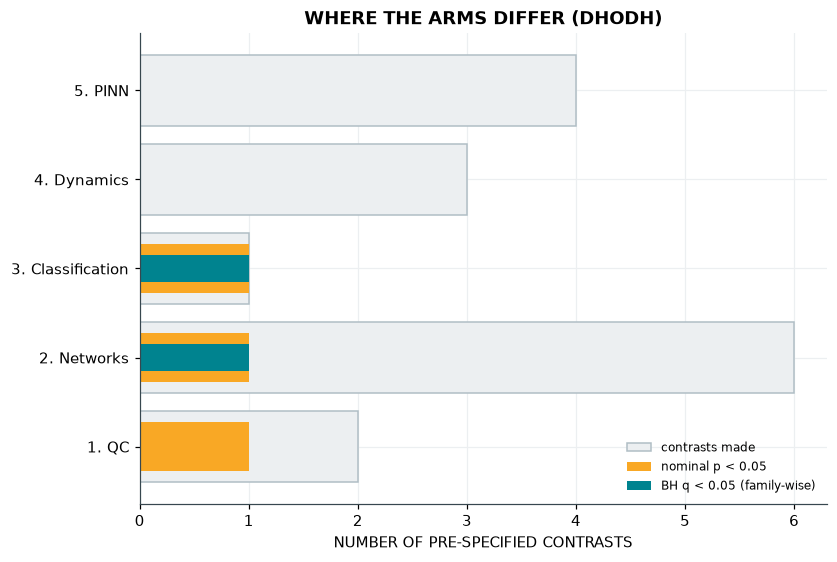

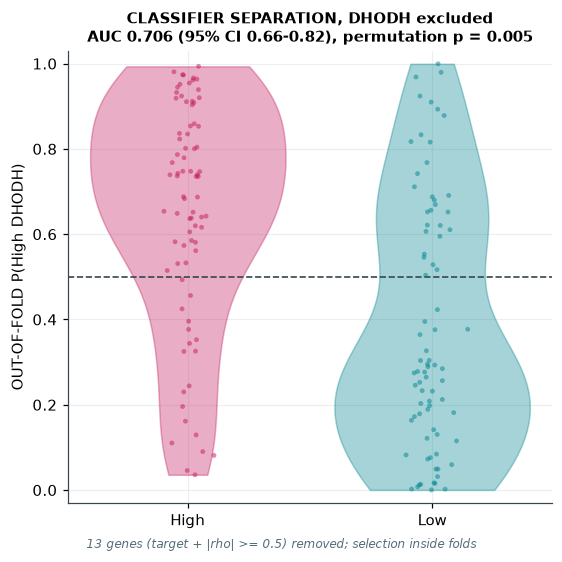

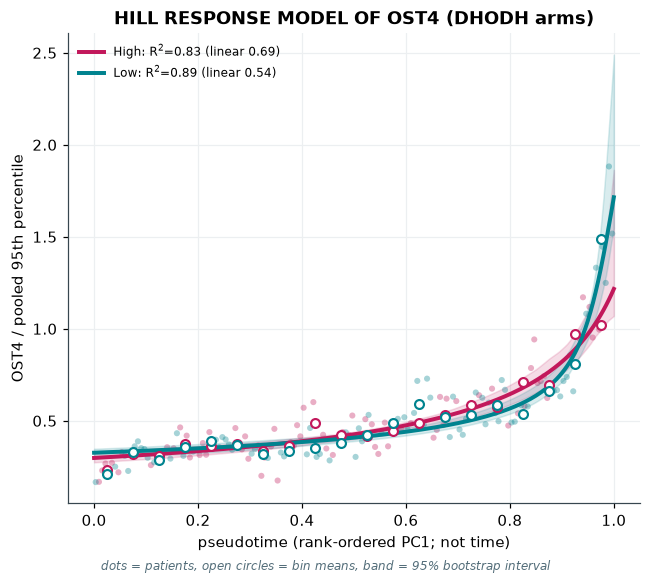

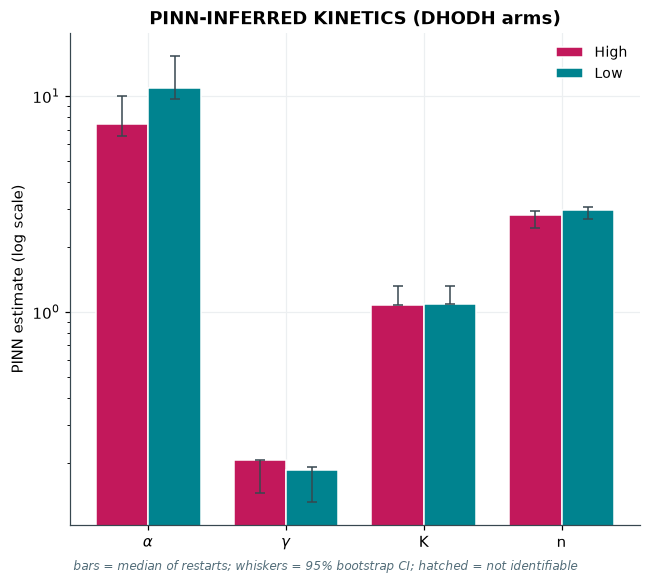

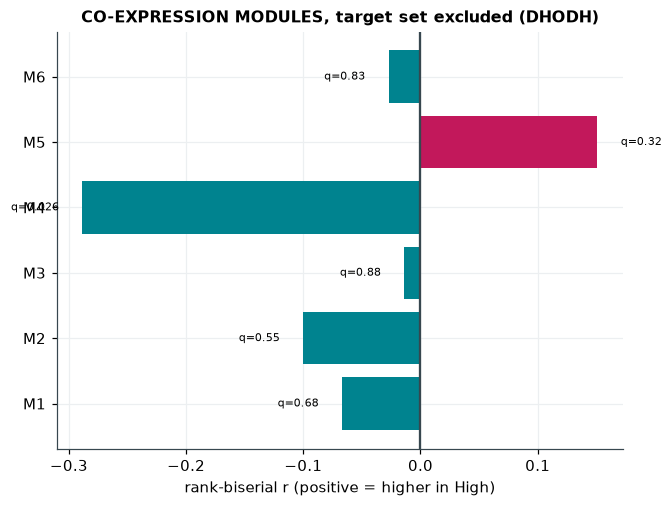

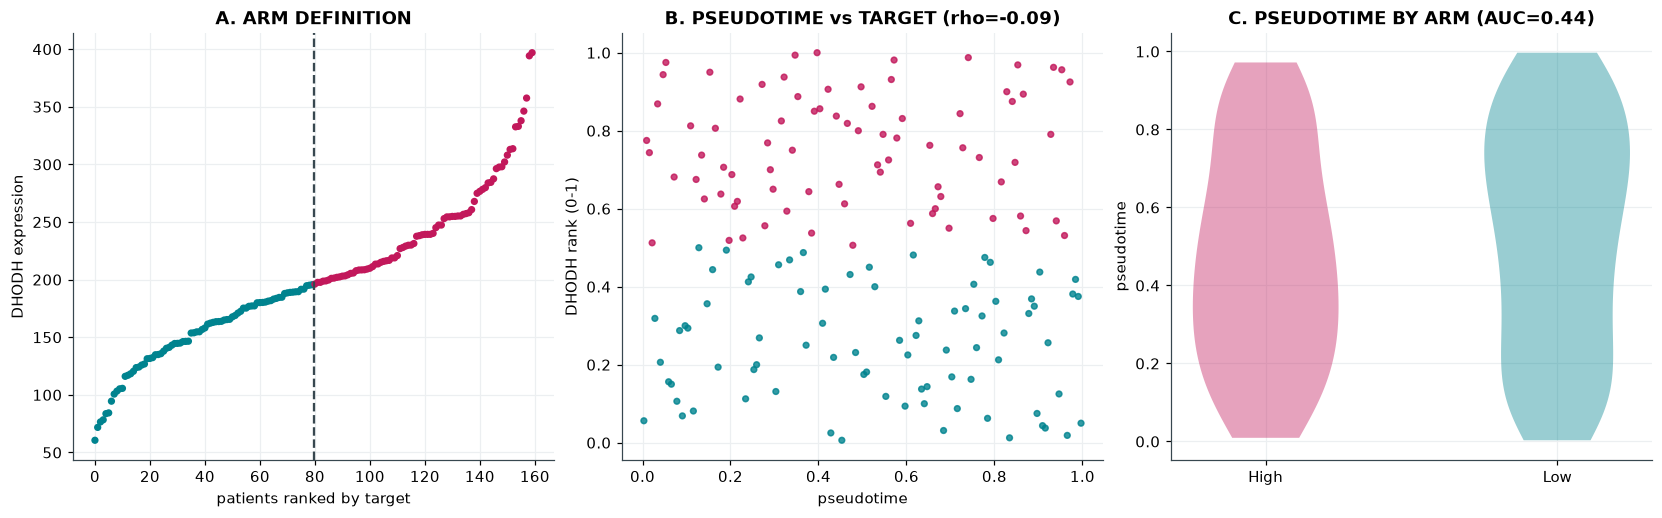

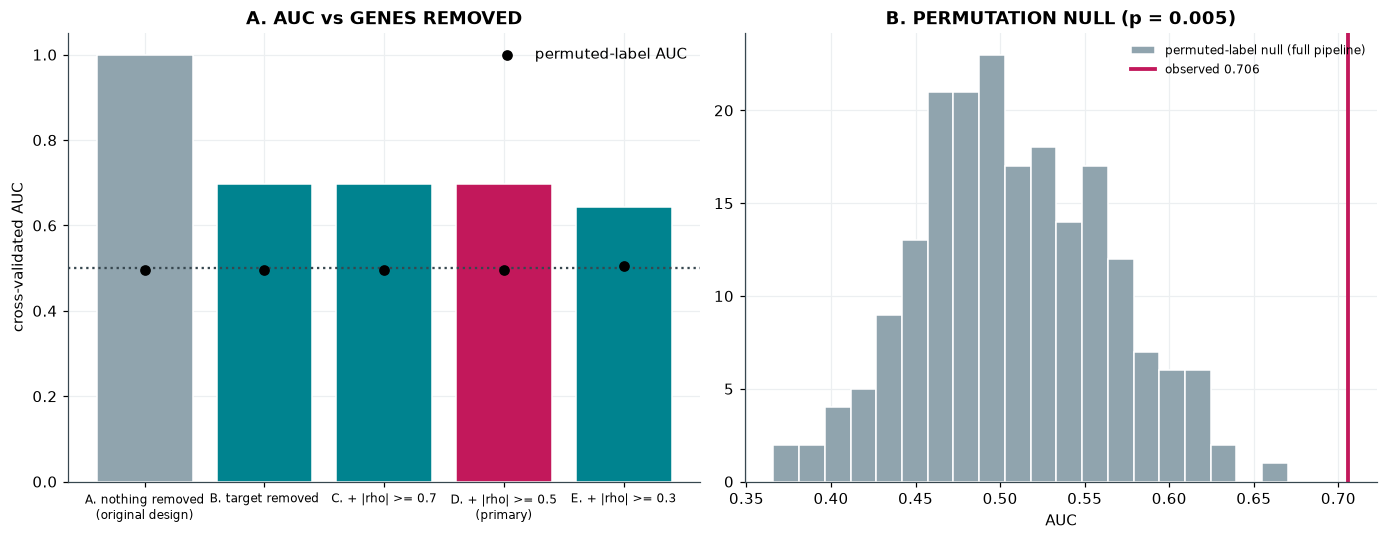

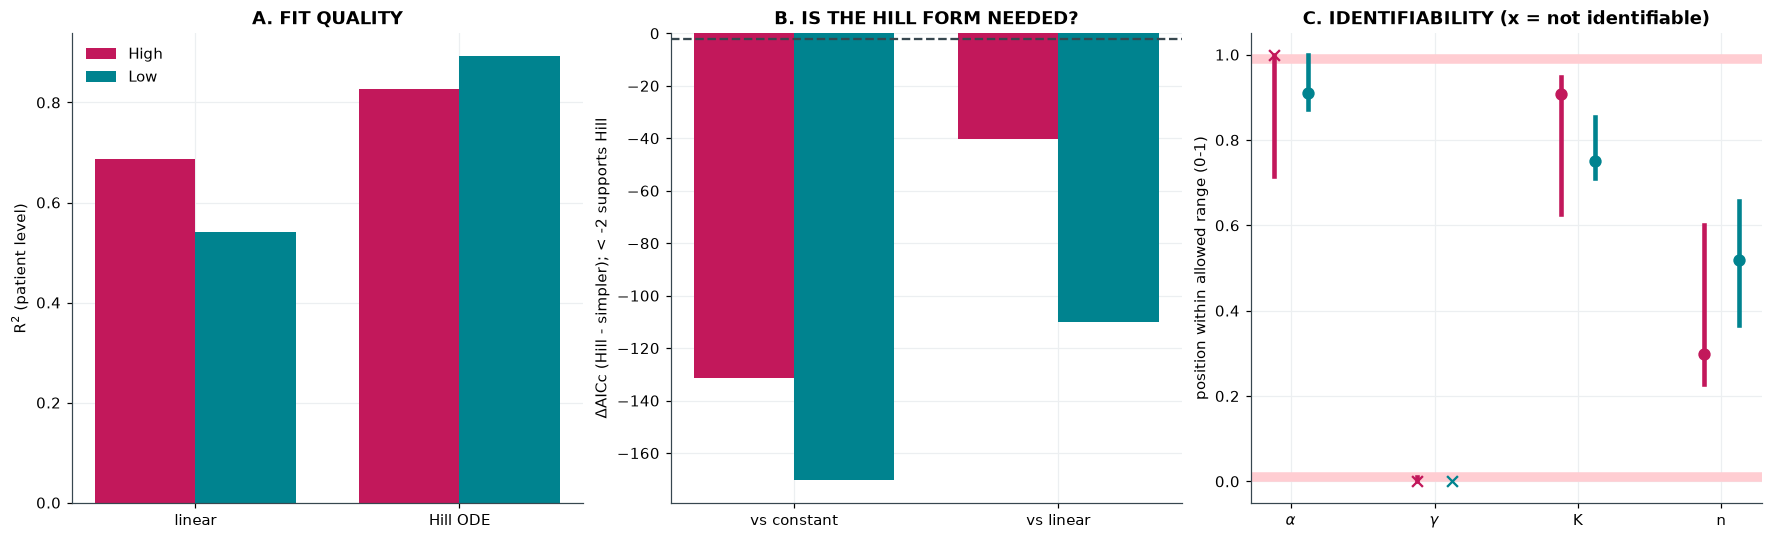

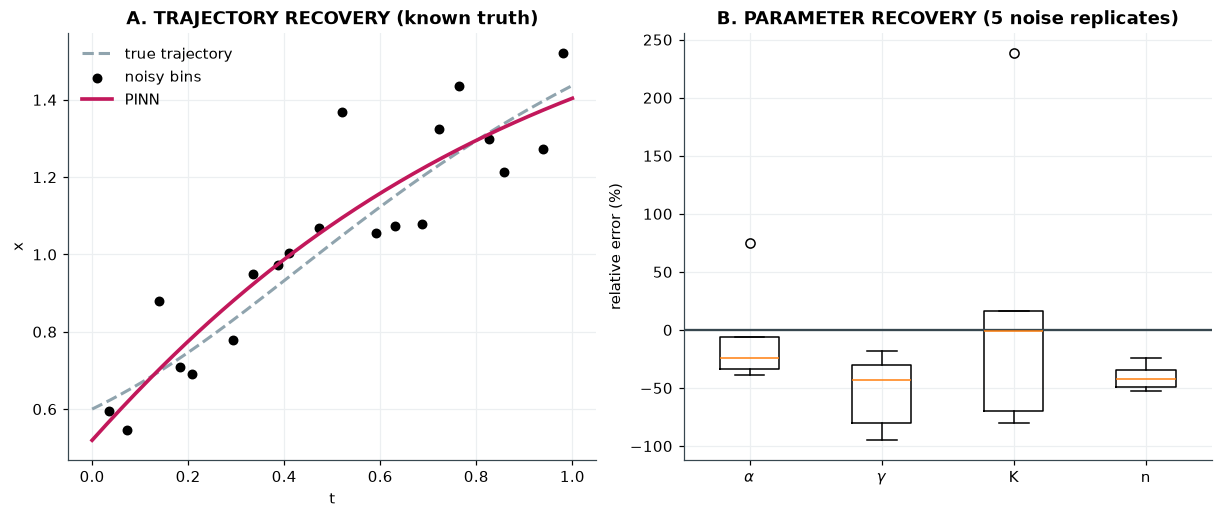

In [7]:
MODULES = ["1. QC", "2. Networks", "3. Classification", "4. Dynamics", "5. PINN"]
C = pd.DataFrame(CONTRASTS)
C["tested"] = C.p_value.apply(lambda v: v is not None and np.isfinite(v))
C["p_value"] = C.p_value.astype(float)
C["q_BH"] = bh(C.p_value.to_numpy())                    # ONE family: all tested contrasts of this run
C["p<0.05"] = C.p_value < 0.05
C["q<0.05"] = C.q_BH < 0.05
TABLES["contrasts_all"] = C
tally = C.groupby("module").agg(made=("tested", "sum"), raw=("p<0.05", "sum"), adj=("q<0.05", "sum")).reindex(MODULES).fillna(0)
print(tally.astype(int).to_string())

# ---- Figure 6 (A/B): where the arms differ
fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
ypos = np.arange(len(MODULES))
ax.barh(ypos, tally["made"], color="#ECEFF1", edgecolor="#B0BEC5", height=0.8, label="contrasts made")
ax.barh(ypos, tally["raw"], color=C_ACC, height=0.55, label="nominal p < 0.05")
ax.barh(ypos, tally["adj"], color=C_LOW, height=0.3, label="BH q < 0.05 (family-wise)")
for i, mname in enumerate(MODULES):
    if tally.loc[mname, "made"] == 0:
        ax.text(0.05, i, "no contrast made", va="center", fontsize=8, style="italic", color="#78909C")
ax.set_yticks(ypos); ax.set_yticklabels(MODULES); ax.set_xlabel("NUMBER OF PRE-SPECIFIED CONTRASTS")
ax.set_title(f"WHERE THE ARMS DIFFER ({TARGET})"); ax.legend(loc="lower right", fontsize=8)
save_fig(fig, f"Fig6_tally_{TARGET}")

# ---- Figure 6 (C/D): leak-free classifier separation
fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
vals = [oof[hi], oof[lo]]
parts = ax.violinplot(vals, showextrema=False, widths=0.8)
for pc, c in zip(parts["bodies"], [C_HIGH, C_LOW]):
    pc.set_facecolor(c); pc.set_alpha(0.35); pc.set_edgecolor(c)
for i, (v, c) in enumerate(zip(vals, [C_HIGH, C_LOW]), 1):
    ax.scatter(i + RNG.normal(0, 0.05, len(v)), v, s=10, color=c, alpha=0.5, edgecolor="none", zorder=3)
ax.axhline(0.5, ls="--", color=C_DARK, lw=1.1); ax.set_ylim(-0.03, 1.03)
ax.set_xticks([1, 2]); ax.set_xticklabels(["High", "Low"]); ax.set_ylabel(f"OUT-OF-FOLD P(High {TARGET})")
ax.set_title(f"CLASSIFIER SEPARATION, {TARGET} excluded\nAUC {auc_obs:.3f} (95% CI {auc_ci[0]:.2f}-{auc_ci[1]:.2f}), "
             f"permutation p = {p_perm:.3f}", fontsize=10)
fig.supxlabel(f"{EXCL.sum():,} genes (target + |rho| >= {CONFIG['RHO_EXCLUDE']}) removed; selection inside folds",
              fontsize=8, style="italic", color="#546E7A")
save_fig(fig, f"Fig6_classifier_{TARGET}")

# ---- Figure 6 (E/F): Hill response model with patient-level data, bootstrap band, fit statistics
fig, ax = plt.subplots(figsize=(5.8, 5.2), constrained_layout=True)
for arm, m in [("High", hi), ("Low", lo)]:
    f = HILL[arm]; c = COL[arm]
    ax.scatter(pt[m], xs[m], s=16, color=c, alpha=0.35, edgecolor="none")
    tb, xb = bin_means(pt[m], xs[m]); ax.scatter(tb, xb, s=34, facecolor="white", edgecolor=c, lw=1.4, zorder=4)
    lo_b, hi_b = np.percentile(BOOTC[arm], [2.5, 97.5], axis=0)
    ax.fill_between(GRID, lo_b, hi_b, color=c, alpha=0.15)
    tag = "" if f["hill_supported"] else "  [Hill form not supported]"
    ax.plot(GRID, hill_curve(f), lw=2.6, color=c, ls="-" if f["hill_supported"] else "--",
            label=f"{arm}: R$^2$={f['r2']:.2f} (linear {f['r2_linear']:.2f}){tag}")
ax.set_xlabel("pseudotime (rank-ordered PC1; not time)"); ax.set_ylabel(f"{HUB_NAME} / pooled 95th percentile")
ax.set_title(f"HILL RESPONSE MODEL OF {HUB_NAME} ({TARGET} arms)"); ax.legend(fontsize=8, loc="upper left")
fig.supxlabel("dots = patients, open circles = bin means, band = 95% bootstrap interval", fontsize=8,
              style="italic", color="#546E7A")
save_fig(fig, f"Fig6_hill_{TARGET}")

# ---- Figure 6 (G/H): PINN estimates with bootstrap CIs and identifiability flags
fig, ax = plt.subplots(figsize=(5.8, 5.2), constrained_layout=True)
if PINN_ON:
    x = np.arange(4); w = 0.38
    for off, arm in [(-w / 2, "High"), (w / 2, "Low")]:
        est = np.array([PINN_POINT[arm][k] for k in PN])
        lo_e = np.array([PINN_IDENT[arm][k]["ci_low"] for k in PN]); hi_e = np.array([PINN_IDENT[arm][k]["ci_high"] for k in PN])
        err = np.vstack([np.clip(est - lo_e, 0, None), np.clip(hi_e - est, 0, None)])
        bars = ax.bar(x + off, est, w, color=COL[arm], edgecolor="white", label=arm, yerr=err,
                      capsize=3, error_kw=dict(ecolor=C_DARK, lw=1))
        for b_, k in zip(bars, PN):
            if not PINN_IDENT[arm][k]["identified"]:
                b_.set_hatch("///"); b_.set_alpha(0.55)
    ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([r"$\alpha$", r"$\gamma$", "K", "n"])
    ax.set_ylabel("PINN estimate (log scale)"); ax.legend(fontsize=9)
    ax.set_title(f"PINN-INFERRED KINETICS ({TARGET} arms)")
    fig.supxlabel("bars = median of restarts; whiskers = 95% bootstrap CI; hatched = not identifiable", fontsize=8,
                  style="italic", color="#546E7A")
else:
    ax.text(.5, .5, "PINN skipped", ha="center"); ax.set_axis_off()
save_fig(fig, f"Fig6_pinn_{TARGET}")

# ---- Figure 6 (supplementary B): module eigengene effect sizes
fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
q_e = C.loc[C.module == "2. Networks", "q_BH"].to_numpy()
ax.barh(EIG_CMP.module, EIG_CMP.rank_biserial, color=[C_HIGH if v > 0 else C_LOW for v in EIG_CMP.rank_biserial])
for i, (v, q) in enumerate(zip(EIG_CMP.rank_biserial, q_e)):
    ax.text(v + 0.02 * np.sign(v), i, f"q={q:.2g}", va="center", ha="left" if v > 0 else "right", fontsize=7.5)
ax.axvline(0, color=C_DARK); ax.set_xlabel("rank-biserial r (positive = higher in High)")
ax.set_title(f"CO-EXPRESSION MODULES, target set excluded ({TARGET})", fontsize=10.5)
save_fig(fig, f"FigS1_modules_{TARGET}")

# ---- Figure S2: arm definition and pseudotime diagnostics (shows the residual circularity explicitly)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
o = np.argsort(t_expr)
axs[0].scatter(np.arange(n_pat), t_expr[o], c=np.where(hi[o], C_HIGH, C_LOW), s=14)
axs[0].axvline(n_pat / 2 - 0.5, ls="--", color=C_DARK); axs[0].set_xlabel("patients ranked by target"); axs[0].set_ylabel(f"{TARGET} expression")
axs[0].set_title("A. ARM DEFINITION")
axs[1].scatter(pt, stats.rankdata(t_expr) / n_pat, c=np.where(hi, C_HIGH, C_LOW), s=14, alpha=0.8)
axs[1].set_xlabel("pseudotime"); axs[1].set_ylabel(f"{TARGET} rank (0-1)")
axs[1].set_title(f"B. PSEUDOTIME vs TARGET (rho={diag.spearman_pseudotime_vs_target[0]:.2f})")
v = [pt[hi], pt[lo]]; pr_ = axs[2].violinplot(v, showextrema=False)
for pc, c in zip(pr_["bodies"], [C_HIGH, C_LOW]):
    pc.set_facecolor(c); pc.set_alpha(0.4)
axs[2].set_xticks([1, 2]); axs[2].set_xticklabels(["High", "Low"]); axs[2].set_ylabel("pseudotime")
axs[2].set_title(f"C. PSEUDOTIME BY ARM (AUC={diag.auc_pseudotime_predicts_arm[0]:.2f})")
save_fig(fig, f"FigS2_pseudotime_diagnostics_{TARGET}")

# ---- Figure S3: leakage sensitivity and permutation null
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
xx = np.arange(len(SENS))
axs[0].bar(xx, SENS.auc, color=[C_NEU, C_LOW, C_LOW, C_HIGH, C_LOW], edgecolor="white")
axs[0].scatter(xx, SENS.permuted_label_auc_mean, color="black", zorder=3, label="permuted-label AUC")
axs[0].axhline(0.5, ls=":", color=C_DARK); axs[0].set_xticks(xx)
axs[0].set_xticklabels([s for s, _, _ in SCEN], fontsize=8); axs[0].set_ylabel("cross-validated AUC"); axs[0].legend()
axs[0].set_title("A. AUC vs GENES REMOVED"); axs[0].set_ylim(0, 1.05)
axs[1].hist(NULL, bins=20, color=C_NEU, edgecolor="white", label="permuted-label null (full pipeline)")
axs[1].axvline(auc_obs, color=C_HIGH, lw=2.5, label=f"observed {auc_obs:.3f}"); axs[1].set_xlabel("AUC")
axs[1].set_title(f"B. PERMUTATION NULL (p = {p_perm:.3f})"); axs[1].legend(fontsize=8)
save_fig(fig, f"FigS3_leakage_sensitivity_{TARGET}")

# ---- Figure S4: model comparison and identifiability of the Hill fit
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
xx = np.arange(2); w = 0.38
for off, arm in [(-w / 2, "High"), (w / 2, "Low")]:
    axs[0].bar(xx + off, [HILL[arm]["r2_linear"], HILL[arm]["r2"]], w, color=COL[arm], label=arm)
axs[0].set_xticks(xx); axs[0].set_xticklabels(["linear", "Hill ODE"]); axs[0].set_ylabel("R$^2$ (patient level)")
axs[0].set_title("A. FIT QUALITY"); axs[0].legend()
for off, arm in [(-w / 2, "High"), (w / 2, "Low")]:
    axs[1].bar(xx + off, [HILL[arm]["aicc_hill"] - HILL[arm]["aicc_const"], HILL[arm]["aicc_hill"] - HILL[arm]["aicc_linear"]], w, color=COL[arm])
axs[1].axhline(-2, ls="--", color=C_DARK); axs[1].set_xticks(xx); axs[1].set_xticklabels(["vs constant", "vs linear"])
axs[1].set_ylabel(r"$\Delta$AICc (Hill - simpler); < -2 supports Hill"); axs[1].set_title("B. IS THE HILL FORM NEEDED?")
for i, k in enumerate(PN):
    for off, arm in [(-0.12, "High"), (0.12, "Low")]:
        d = IDENT[arm][k]
        f_ = (lambda v: v) if k == "n" else np.log
        lo_, hi_ = HILL_BOUNDS[k]; pos = lambda v: (f_(v) - f_(lo_)) / (f_(hi_) - f_(lo_))
        axs[2].plot([i + off] * 2, [pos(d["ci_low"]), pos(d["ci_high"])], color=COL[arm], lw=3)
        axs[2].scatter(i + off, d["position_in_bounds"], color=COL[arm], marker="o" if d["identified"] else "x", s=50, zorder=3)
axs[2].axhspan(0, 0.02, color="#FFCDD2"); axs[2].axhspan(0.98, 1, color="#FFCDD2")
axs[2].set_xticks(range(4)); axs[2].set_xticklabels([r"$\alpha$", r"$\gamma$", "K", "n"])
axs[2].set_ylabel("position within allowed range (0-1)"); axs[2].set_title("C. IDENTIFIABILITY (x = not identifiable)")
save_fig(fig, f"FigS4_hill_model_checks_{TARGET}")

# ---- Figure S5: PINN validation on synthetic data with known parameters
if PINN_ON and VAL is not None:
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
    axs[0].plot(GRID, truth, "--", color=C_NEU, lw=2, label="true trajectory")
    axs[0].scatter(VAL["t"], VAL["x"], s=30, color="black", label="noisy bins")
    axs[0].plot(GRID, VAL["predict"](GRID), color=C_HIGH, lw=2.4, label="PINN"); axs[0].legend()
    axs[0].set_xlabel("t"); axs[0].set_ylabel("x"); axs[0].set_title("A. TRAJECTORY RECOVERY (known truth)")
    axs[1].boxplot([VALT.loc[VALT.parameter == k, "rel_error_pct"] for k in PN])
    axs[1].set_xticks(range(1, 5)); axs[1].set_xticklabels([r"$\alpha$", r"$\gamma$", "K", "n"])
    axs[1].axhline(0, color=C_DARK); axs[1].set_ylabel("relative error (%)")
    axs[1].set_title(f"B. PARAMETER RECOVERY ({CONFIG['N_VALID_REPS']} noise replicates)")
    save_fig(fig, f"FigS5_pinn_validation_{TARGET}")

## 8. Export every table to one workbook and record the run

In [8]:
meta = pd.DataFrame([("target", TARGET), ("patients", n_pat), ("genes", n_gen), ("excluded_genes", int(EXCL.sum())),
                     ("python", sys.version.split()[0]), ("numpy", np.__version__), ("pandas", pd.__version__),
                     ("config", json.dumps({k: v for k, v in CONFIG.items()}, default=str))],
                    columns=["item", "value"])
with pd.ExcelWriter(OUT / f"results_{TARGET}.xlsx", engine="openpyxl") as xw:
    meta.to_excel(xw, sheet_name="run_info", index=False)
    for name, df in TABLES.items():
        df.to_excel(xw, sheet_name=name[:31], index=False)
print(f"tables -> {OUT / f'results_{TARGET}.xlsx'} ; figures -> {OUT}")

tables -> Results/DHODH/results_DHODH.xlsx ; figures -> Results/DHODH
